# 434 Lab 4 Report

**Name:** Austin Birkhofer

## Data

In [7]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats
import h5py
from pathlib import Path
import pandas as pd
from matplotlib.colors import LogNorm
from IPython.display import display, Markdown

In [11]:
hf = h5py.File('../434Labs/gammaray_lab4.h5', 'r')

In [12]:
hf.keys()

<KeysViewHDF5 ['data']>

In [13]:
data = np.array(hf.get('data'))

In [14]:
np.shape(data)
data[:,0]

array([9.40680016e+08, 3.15000000e+02, 4.50000000e+01, 1.00000000e+01])

In [15]:
hf.close()

## Problem

### Part 1

Four rows contain GPS time, solar phase, Earth longitude, and counts per 0.1s. The data cover 30 days with 25,920,001 observations.

shape: (4, 25920001), duration: 30.0 days


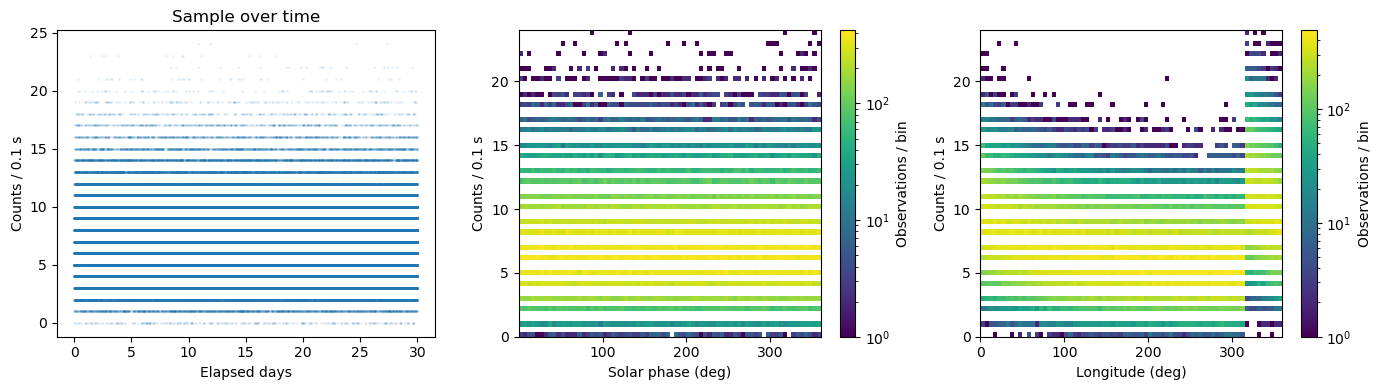

In [26]:
rng = np.random.default_rng(43404)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
records = data.shape[1]

def read_rows(start, stop):
    return data[:, start:stop].T

indices = np.sort(rng.choice(records, min(200000, records), replace=False))
sample = data[:, indices].T
train = (indices // 10000) % 5 != 0
training, validation = sample[train], sample[~train]
t0 = data[0, 0]
print(f"shape: {data.shape}, duration: {(data[0,-1]-t0)/86400:.1f} days")
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].scatter((sample[:,0]-t0)/86400, sample[:,3], s=1, alpha=.08)
axes[0].set(xlabel="Elapsed days", ylabel="Counts / 0.1 s", title="Sample over time")
for ax, col, label in zip(axes[1:], [1, 2], ["Solar phase (deg)", "Longitude (deg)"]):
    h = ax.hist2d(sample[:,col] % 360, sample[:,3], bins=(72, 60), norm=LogNorm())
    fig.colorbar(h[3], ax=ax, label="Observations / bin")
    ax.set(xlabel=label, ylabel="Counts / 0.1 s")
fig.tight_layout(); plt.show()

I observe that in the longitude plot, we see that the count distribution rises a lot near 315°. No obvious signal contamination is observed, but I cannot see short bursts because of my sample size (200k). I plan to estimate EV as a function of longitude which changes with time, and I will use a Poisson distribution (because we are counting particles over fixed intervals of time) with that changing mean as a beginner background model!

### Part 2

I grouped training exposures into 0.5° longitdue bins and calculate the mean count in each bin. Background rises a lot at 315°, and then decays until the next passage. I fit

$$\mu(\lambda)=b+A e^{-\Delta\lambda/L},\qquad
\Delta\lambda=(\lambda-\lambda_0)\bmod360^\circ.$$

This gets us $b=5.699$, $A=5.696$, and $L=90.049^\circ$. The 90-minute longitude cycle makes the decay time about 22.5 minutes. Expected counts range from about 5.80 to 11.40 per exposure. There is little visible solar phase dependence after thinking abiout longitude.

Entry longitude: 315.0°
Baseline = 5.6991; amplitude = 5.6960
Decay scale = 90.049°; decay time = 22.512 min
Longitude cycle = 90.000 min


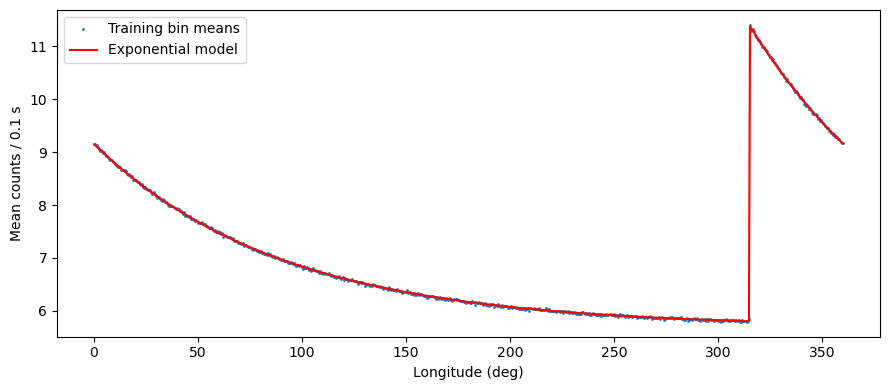

In [27]:
from scipy.optimize import curve_fit
edges = np.linspace(0, 360, 721)
centers = (edges[:-1] + edges[1:]) / 2
number = np.zeros(720)
total = np.zeros(720)
CHUNK = 500_000
for start in range(0, records, CHUNK):
    rows = read_rows(start, min(start+CHUNK, records))
    ids = np.arange(start, start+len(rows))
    rows = rows[(ids//10000) % 5 != 0]
    number += np.histogram(rows[:,2] % 360, edges)[0]
    total += np.histogram(rows[:,2] % 360, edges, weights=rows[:,3])[0]
assert np.all(number > 0)
means = total / number
entry = edges[np.argmax(np.diff(np.r_[means[-1], means]))]

def background(longitude, base, amplitude, scale):
    return base + amplitude*np.exp(-((longitude-entry) % 360)/scale)

parameters, covariance = curve_fit(background, centers, means,
    p0=[5.5, 6, 90], sigma=np.sqrt(means/number), absolute_sigma=True,
    bounds=([0,0,.1], [100,100,1000]))
speed = np.median((np.diff(data[2,:10000])+180) % 360-180) / np.median(np.diff(data[0,:10000]))
print(f"Entry longitude: {entry:.1f}°")
print(f"Baseline = {parameters[0]:.4f}; amplitude = {parameters[1]:.4f}")
print(f"Decay scale = {parameters[2]:.3f}°; decay time = {parameters[2]/speed/60:.3f} min")
print(f"Longitude cycle = {360/speed/60:.3f} min")
plt.figure()
plt.plot(centers, means, '.', ms=2, label="Training bin means")
plt.plot(centers, background(centers,*parameters), 'r-', label="Exponential model")
plt.xlabel("Longitude (deg)"); plt.ylabel("Mean counts / 0.1 s")
plt.legend(); plt.tight_layout(); plt.show()

### Part 3

I used $K_i\sim\mathrm{Poisson}(\mu_i)$, with $\mu_i$ set by the longitude at this time. This predicts both the changing mean and counting variance, and complete time blocks are held out from fitting.

The 40,038 held-out observations give a mean error of 0.0063 counts, an RMSE of 2.666, and standardized residuals with mean 0.0020 and standard deviation 0.9989, and these agree with Poisson counting noise. A time binned comparison checks for drift amd the longitude plot above checks the repeating shape. This verifies the central distribution but does not establish the accuracy of extremely small tail probabilities!

Held-out observations: 40,038
Mean error: 0.00634; RMSE: 2.66625
Standardized residual mean: 0.00196; SD: 0.99888


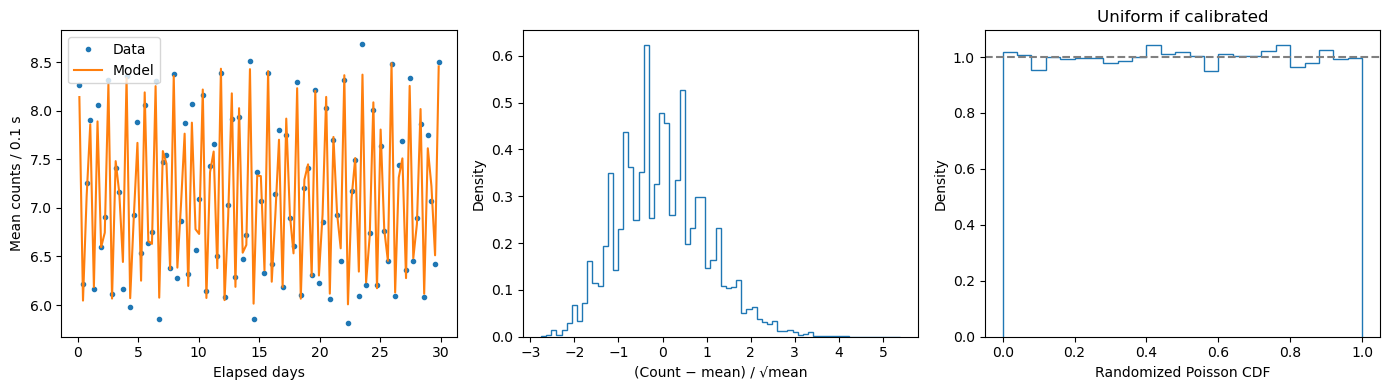

In [28]:
mu = background(validation[:,2], *parameters)
y = validation[:,3]
residual = (y-mu)/np.sqrt(mu)
print(f"Held-out observations: {len(y):,}")
print(f"Mean error: {np.mean(y-mu):.5f}; RMSE: {np.sqrt(np.mean((y-mu)**2)):.5f}")
print(f"Standardized residual mean: {residual.mean():.5f}; SD: {residual.std():.5f}")
# Compare averages over the same held-out exposures.
time_edges = np.linspace(data[0,0], data[0,-1], 101)
occupancy = np.histogram(validation[:,0], time_edges)[0]
observed = np.histogram(validation[:,0], time_edges, weights=y)[0]/occupancy
predicted = np.histogram(validation[:,0], time_edges, weights=mu)[0]/occupancy
time_centers = (time_edges[:-1]+time_edges[1:])/2
lower = stats.poisson.cdf(y-1, mu)
pit = lower + rng.random(len(y))*(stats.poisson.cdf(y,mu)-lower)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot((time_centers-t0)/86400, observed, '.', label="Data")
axes[0].plot((time_centers-t0)/86400, predicted, '-', label="Model")
axes[0].set(xlabel="Elapsed days", ylabel="Mean counts / 0.1 s"); axes[0].legend()
axes[1].hist(residual, bins=70, density=True, histtype="step")
axes[1].set(xlabel="(Count − mean) / √mean", ylabel="Density")
axes[2].hist(pit, bins=25, density=True, histtype="step")
axes[2].axhline(1, color="gray", ls="--")
axes[2].set(xlabel="Randomized Poisson CDF", ylabel="Density", title="Uniform if calibrated")
fig.tight_layout(); plt.show()

### Part 4

For each 0.1-second exposure, I use the background mean predicted at that longitude. The one-sided five-sigma probability is

$$\alpha=1-\Phi(5)\approx2.87\times10^{-7}.$$

The threshold is the smallest integer $k_{\rm crit}$ satisfying

$$P(K\ge k_{\rm crit}\mid\mu(t))\le\alpha.$$

The threshold varies from abut 22 to 33 total particles / exposure over the orbit. A higher background needs a higher count to be unusual. These are total counts, and the excess above background is $k_{\rm crit}-\mu(t)$.

,GPS time,Elapsed days,Longitude (deg),Expected background,5-sigma total count threshold,Excess above background
0,940680024.4,0.000097,45.560000,7.782649,26,18.217351
1,941006033.4,3.773350,179.493333,6.169892,23,16.830108
2,941330308.3,7.526531,197.820000,6.083189,23,16.916811
3,941651689.8,11.246225,23.253333,8.368341,27,18.631659
4,941971098.7,14.943087,77.180000,7.165663,25,17.834337
5,942299647.7,18.745737,20.446667,8.452848,28,19.547152
6,942626744.3,22.531578,226.886667,5.977218,23,17.022782
7,942949777.6,26.270389,162.440000,6.268060,23,16.731940
8,943272015.1,29.999990,44.940000,7.797044,26,18.202956


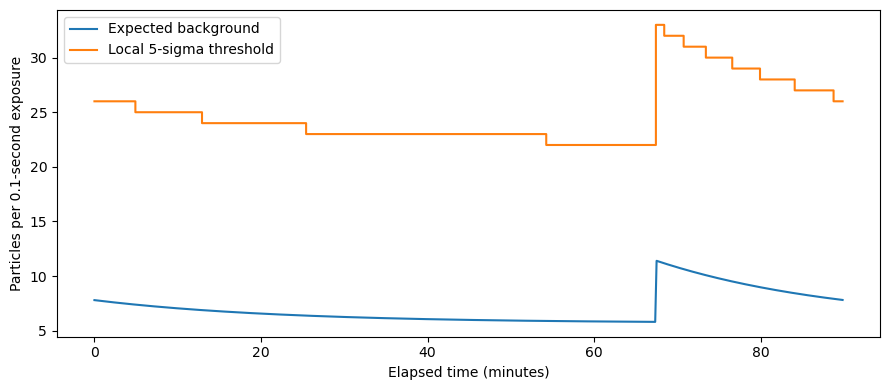

Threshold range: 22–33 particles per exposure


In [31]:
alpha = stats.norm.sf(5)

def threshold(mu):
    mu = np.asarray(mu)
    k = stats.poisson.isf(alpha, mu).astype(int) + 1
    return k

# show thresholds at actual observation times across the month
chosen = np.linspace(0, len(sample) - 1, 9).astype(int)
rows = sample[chosen]
expected = background(rows[:, 2], *parameters)
critical = threshold(expected)

display(pd.DataFrame({
    "GPS time": rows[:, 0],
    "Elapsed days": (rows[:, 0] - t0) / 86400,
    "Longitude (deg)": rows[:, 2],
    "Expected background": expected,
    "5-sigma total count threshold": critical,
    "Excess above background": critical - expected
}))

# plot one complete longitude cycle
cycle_seconds = 360 / speed
stop = np.searchsorted(data[0], t0 + cycle_seconds)
orbit = data[:, :stop:100].T

orbit_mean = background(orbit[:, 2], *parameters)
orbit_threshold = threshold(orbit_mean)

plt.figure(figsize=(9, 4))
plt.plot((orbit[:, 0] - t0) / 60, orbit_mean,
         label="Expected background")
plt.step((orbit[:, 0] - t0) / 60, orbit_threshold,
         where="mid", label="Local 5-sigma threshold")
plt.xlabel("Elapsed time (minutes)")
plt.ylabel("Particles per 0.1-second exposure")
plt.legend()
plt.tight_layout()
plt.show()

# check the threshold range over a finely sampled longitude cycle.
longitude = np.linspace(0, 360, 36000, endpoint=False)
limits = threshold(background(longitude, *parameters))
print(f"Threshold range: {limits.min()}–{limits.max()} particles per exposure")

### Part 5

The background rises near $315^\circ$, or $45^\circ$ west longitude, and then decays before repeating about 90 minutes later. I think this might be due to the South Atlantic Anomaly which is an area where low orbit satellites are exposed to increased charged particles.

One possible mechanism is activation of detector or spacecraft material. Particle interactions create radioactive products and these continue making background detections after the passage. Their decay can make the observed exponential decrease so we get

$$\mu(t)=b+A e^{-(t-t_{\rm entry})/\tau}$$

between passages. The fitted effective decay time is approximately 22.5 minutes. Repeated passages replenish the excess.